# TJ Smith
#### Coded with assistance from Claude

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


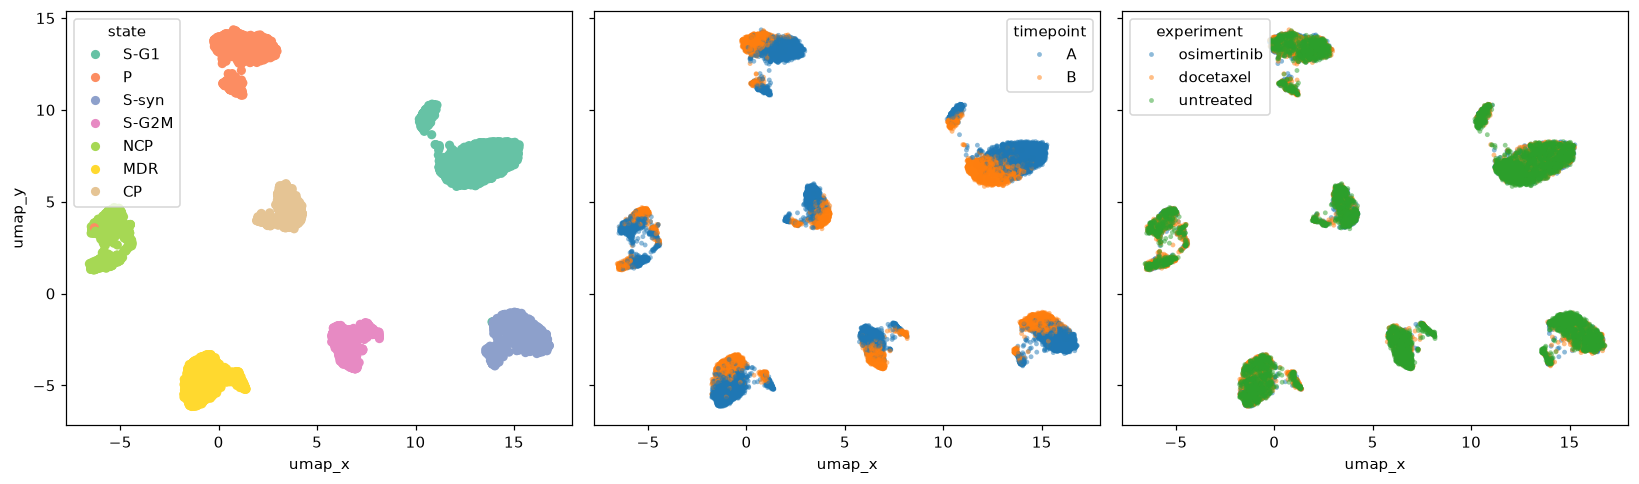

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

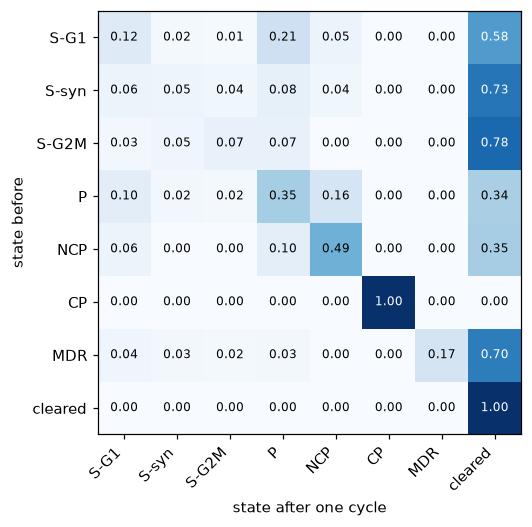

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*

CP is absorbing under osimertinib, so the medication cannot kill CP cells. This means that CP is resistant to osimertinib, so more treatments are required to also kill CP cells.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

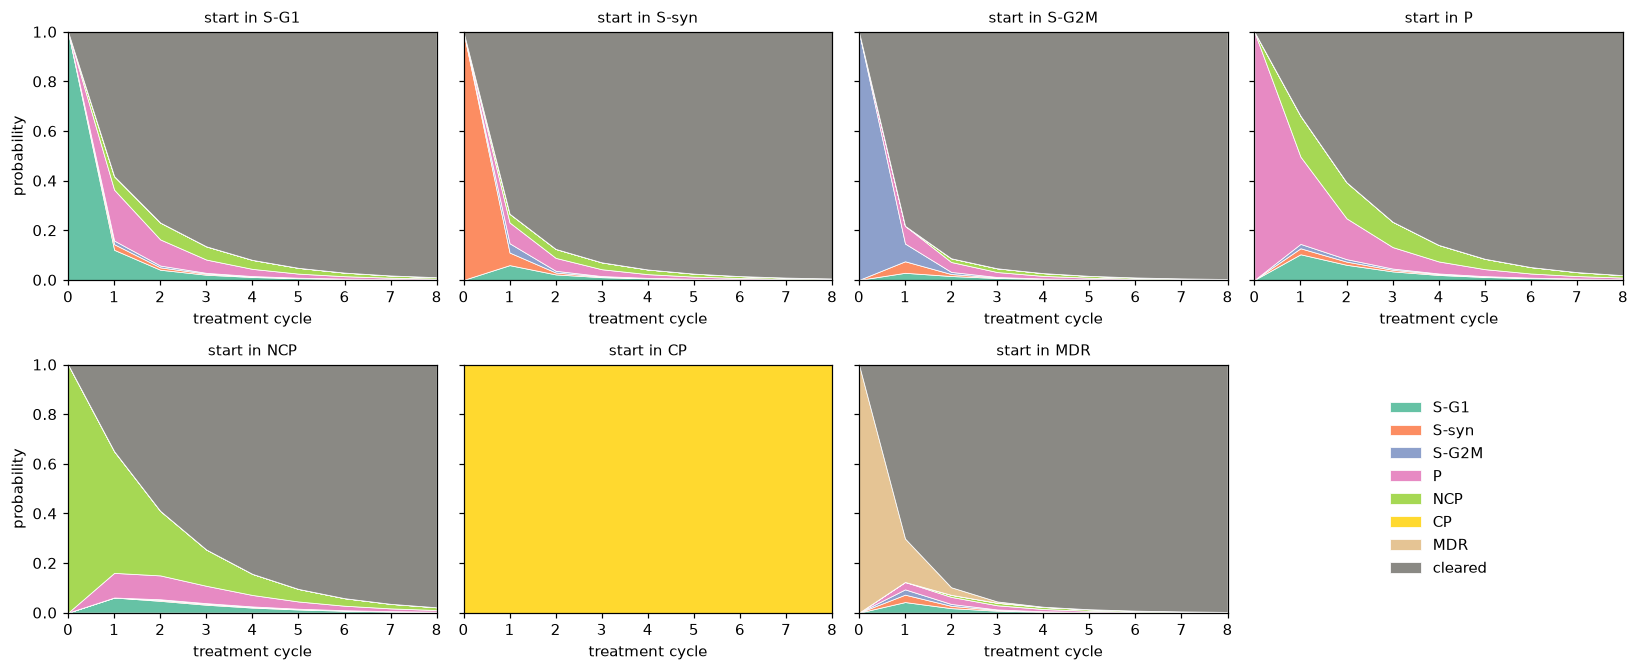

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



S-G1, S-syn, S-G2M, P, NCP, and MDR eventually clear with osimertinib. CP is the only one that survives.

The tumor that lasts the longest out of the ones that are cleared is NCP.

The starting state that sticks around for the most cycles is CP because it never clears.

The starting state that results in the highest proportion of alive cells after three cycles is also CP. Second to CP is NCP.

In [ ]:
# fraction of cells still alive (not cleared) after each cycle, for each starting state
P_osi_np = P_hat.to_numpy()
alive = pd.DataFrame({s: 1 - evolve(basis(s, P_hat), P_osi_np, 50)[:, -1] for s in STATES})
alive.index.name = "cycle"
display(alive.round(3).head(9))

# Q1: which starting states are eventually cleared (alive -> 0) vs survive?
print("alive after 50 cycles:\n", alive.iloc[50].round(4))
cleared_states = [s for s in STATES if alive[s].iloc[50] < 1e-3]
surviving_states = [s for s in STATES if s not in cleared_states]
print("eventually cleared:", cleared_states)
print("survive:", surviving_states)

# Q2: of the clearable states, which lasts longest?
Q = P_hat.loc[cleared_states, cleared_states].to_numpy()
N = np.linalg.inv(np.eye(len(Q)) - Q)
expected_cycles = pd.Series(N.sum(axis=1), index=cleared_states).sort_values(ascending=False)
print("expected cycles alive before clearing:\n", expected_cycles.round(2))
print("cycle when <1% alive:", {s: int((alive[s] < 0.01).idxmax()) for s in cleared_states})

# Q3: which state sticks around longest?  -> any surviving state never clears
print("never cleared:", surviving_states)

# Q4: highest proportion alive after 3 cycles
print("alive after 3 cycles:\n", alive.loc[3].sort_values(ascending=False).round(3))


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR
cycle,,,,,,,
0,1.000,1.000,1.000,1.000,1.000,1.0,1.000
1,0.418,0.267,0.218,0.662,0.651,1.0,0.299
2,0.231,0.125,0.087,0.393,0.410,1.0,0.102
3,0.135,0.071,0.047,0.234,0.254,1.0,0.045
4,0.081,0.042,0.027,0.141,0.156,1.0,0.024
5,0.049,0.025,0.016,0.085,0.096,1.0,0.014
6,0.029,0.015,0.010,0.052,0.058,1.0,0.008
7,0.018,0.009,0.006,0.031,0.035,1.0,0.005
8,0.011,0.006,0.004,0.019,0.022,1.0,0.003


alive after 50 cycles:
 S-G1     0.0
S-syn    0.0
S-G2M    0.0
P        0.0
NCP      0.0
CP       1.0
MDR      0.0
Name: 50, dtype: float64
eventually cleared: ['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'MDR']
survive: ['CP']
expected cycles alive before clearing:
 NCP      2.72
P        2.65
S-G1     1.99
S-syn    1.57
MDR      1.50
S-G2M    1.42
dtype: float64
cycle when <1% alive: {'S-G1': 9, 'S-syn': 7, 'S-G2M': 6, 'P': 10, 'NCP': 10, 'MDR': 6}
never cleared: ['CP']
alive after 3 cycles:
 CP       1.000
NCP      0.254
P        0.234
S-G1     0.135
S-syn    0.071
S-G2M    0.047
MDR      0.045
Name: 3, dtype: float64


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

pi_0: {'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


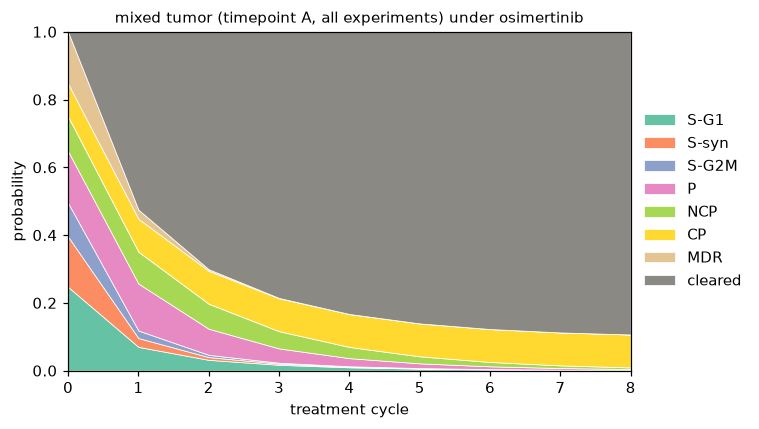

In [17]:
# Your code here
# starting vector: fraction of each state among ALL timepoint-A cells (all three experiments)
# reindex to OUTCOMES so the order matches P_hat's columns; "cleared" starts at 0
pi_mix = (cells.loc[cells.timepoint == "A", "state"]
               .value_counts(normalize=True)
               .reindex(OUTCOMES, fill_value=0)
               .to_numpy())
print("pi_0:", dict(zip(OUTCOMES, pi_mix.round(3))))

# evolve pi_mix and plot the results
traj_mix = evolve(pi_mix, P_hat.to_numpy(), N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(traj_mix, ax, "mixed tumor (timepoint A, all experiments) under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP dominates the remaining cluster, and they will never be cleared by osimertinib. The long-run endpoint comes from the transition matrix because the only two absorbing states remaining are cleared and CP - every other state has a positive probability of reaching cleared. If you take the limit of P_hat, all of the states become cleared except for CP. So, the endpoint depends on the starting vector for the transition matrix.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [18]:
##Add code here
def transition_matrix(experiment):
    '''Estimate the 8x8 transition matrix (with absorbing "cleared" row) for one experiment. Written with Claude.'''
    sub = cells[cells["experiment"] == experiment]
    at_A = sub[sub.timepoint == "A"][["lineage_tag", "state"]]
    at_B = sub[sub.timepoint == "B"][["lineage_tag", "state"]]
    pr = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pr["state_B"] = pr["state_B"].fillna("cleared")
    cnt = (pd.crosstab(pr.state_A, pr.state_B)
             .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = cnt.div(cnt.sum(axis=1), axis=0)
    P.loc["cleared"] = pd.Series({c: (1 if c == "cleared" else 0) for c in OUTCOMES})
    assert np.allclose(P.sum(axis=1), 1), "Every row should sum to 1."
    return P

P_doc_df = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()
P_doc = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

# which states are (approximately) absorbing? -> self-transition probability on the diagonal
display(pd.DataFrame({"osimertinib": np.diag(P_osi), "docetaxel": np.diag(P_doc),
                      "holiday": np.diag(P_holiday)}, index=OUTCOMES).round(3))


,osimertinib,docetaxel,holiday
S-G1,0.121,0.293,0.412
S-syn,0.051,0.111,0.342
S-G2M,0.071,0.035,0.269
P,0.352,0.409,0.324
NCP,0.490,0.436,0.478
CP,1.000,0.100,0.820
MDR,0.175,1.000,0.542
cleared,1.000,1.000,1.000


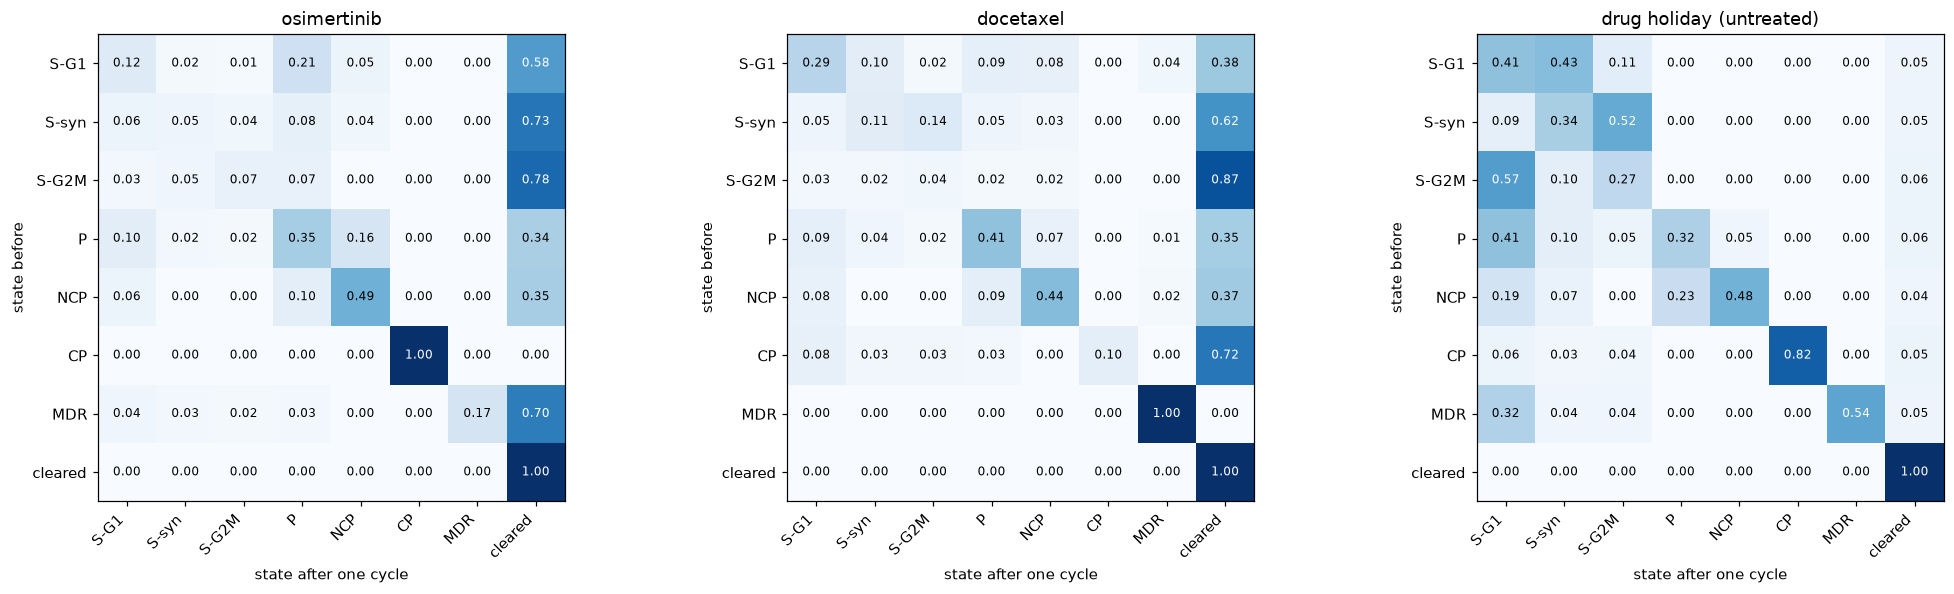

In [19]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
show_matrix(P_hat, "osimertinib", ax=axes[0])
show_matrix(P_doc_df, "docetaxel", ax=axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", ax=axes[2])
plt.tight_layout()
plt.show()


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


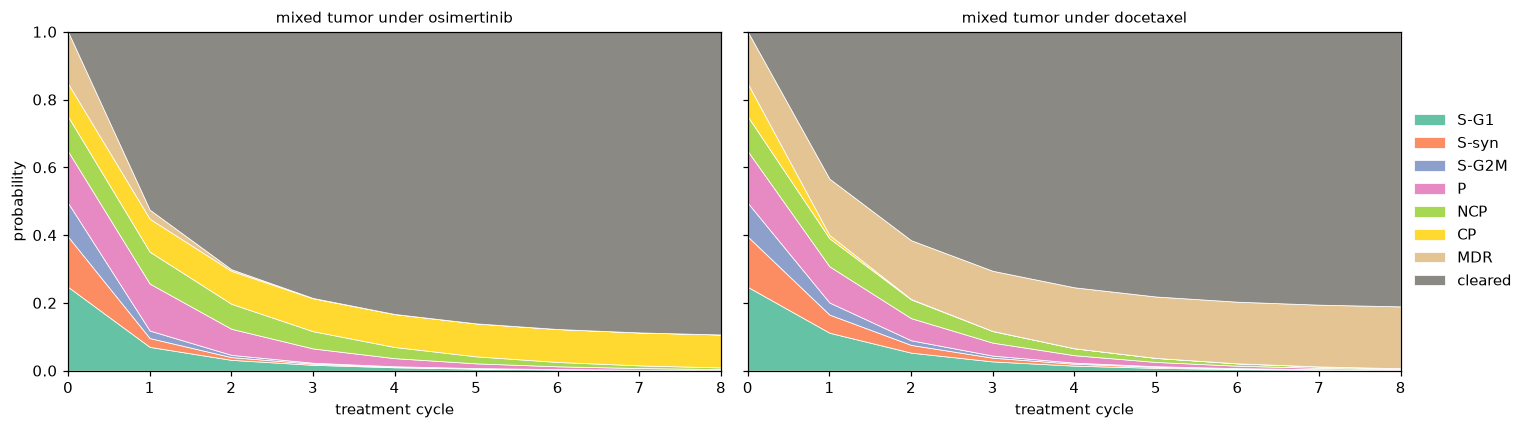

fraction alive after 8 cycles of docetaxel: 0.19
share of surviving cells by state: {'S-G1': np.float64(0.008), 'S-syn': np.float64(0.003), 'S-G2M': np.float64(0.002), 'P': np.float64(0.012), 'NCP': np.float64(0.012), 'CP': np.float64(0.0), 'MDR': np.float64(0.963)}
long run (50 cycles): {'S-G1': np.float64(0.0), 'S-syn': np.float64(0.0), 'S-G2M': np.float64(0.0), 'P': np.float64(0.0), 'NCP': np.float64(0.0), 'CP': np.float64(0.0), 'MDR': np.float64(0.183), 'cleared': np.float64(0.817)}


In [20]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_trajectory(evolve(pi_mix, P_osi, N_CYCLES), axes[0], "mixed tumor under osimertinib")
plot_trajectory(traj_doc, axes[1], "mixed tumor under docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

alive = 1 - traj_doc[:, -1]
print("fraction alive after 8 cycles of docetaxel:", alive[-1].round(3))
print("share of surviving cells by state:",
      dict(zip(OUTCOMES[:-1], (traj_doc[-1, :-1] / alive[-1]).round(3))))
print("long run (50 cycles):", dict(zip(OUTCOMES, evolve(pi_mix, P_doc, 50)[-1].round(3))))


*Answer questions in markdown here.*
1. Docetaxel is able to clear CP unlike osimertinib, however this time it is unable to clear MDR (which is absorbing). It also appears that some cells move into MDR during treatment, which is unlike CP which other cells could not transform into. So MDR levels increased throughout treatment under docetaxel, whereas CP remained the same. Under Drug Holiday, there waas no abosrbing state other than cleared. There is a small amount of cells that move to cleared each cycle, and we can see that some cells simply progress through the cell cycle, and some cells that start out resistant become sensitive again.


2. Under doceetaxel, CP is eliminated quickly to cleared (in around 2 cycles). However, MDR grows, and the long-run endpoint includes around 20% MDR and 80% cleared.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

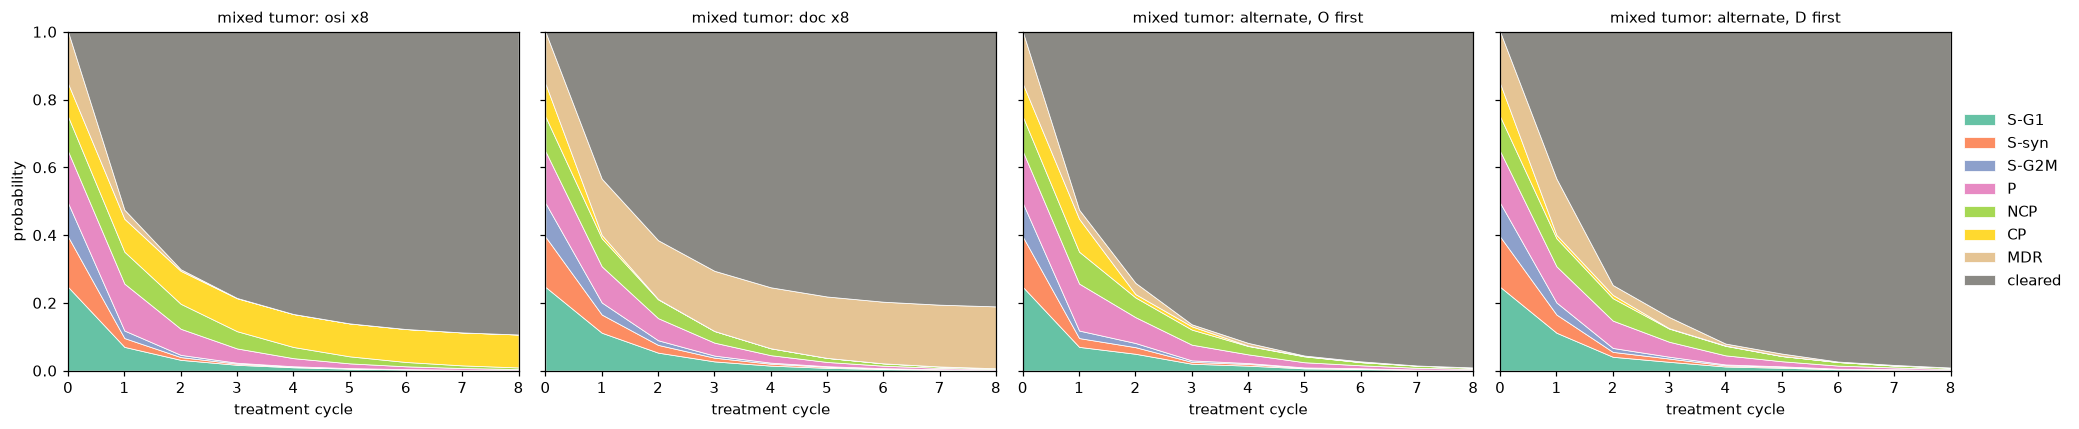

fraction of mixed tumor still alive after each round:


,osi x8,doc x8,"alternate, O first","alternate, D first"
round,,,,
0,1.0000,1.0000,1.0000,1.0000
1,0.4749,0.5665,0.4749,0.5665
2,0.2992,0.3849,0.2591,0.2526
3,0.2144,0.2946,0.1367,0.1582
4,0.1672,0.2460,0.0820,0.0800
5,0.1394,0.2188,0.0445,0.0504
6,0.1228,0.2034,0.0275,0.0268
7,0.1127,0.1946,0.0151,0.0168
8,0.1066,0.1896,0.0094,0.0092


alternate, O first: alive after 8 = 0.0094  |  survivors: {'S-G1': np.float64(0.0016), 'S-syn': np.float64(0.0005), 'S-G2M': np.float64(0.0003), 'P': np.float64(0.003), 'NCP': np.float64(0.0033), 'CP': np.float64(0.0), 'MDR': np.float64(0.0007)}
alternate, D first: alive after 8 = 0.0092  |  survivors: {'S-G1': np.float64(0.0014), 'S-syn': np.float64(0.0003), 'S-G2M': np.float64(0.0002), 'P': np.float64(0.0031), 'NCP': np.float64(0.0038), 'CP': np.float64(0.0), 'MDR': np.float64(0.0003)}
fraction alive after 8 rounds, by starting state:


,osi x8,doc x8,"alternate, O first","alternate, D first"
mix,0.1066,0.1896,0.0094,0.0092
S-G1,0.0108,0.0727,0.0099,0.0109
S-syn,0.0056,0.0124,0.0051,0.0047
S-G2M,0.0036,0.0059,0.0032,0.0021
P,0.0190,0.0545,0.0170,0.0154
NCP,0.0216,0.0681,0.0190,0.0172
CP,1.0000,0.0101,0.0064,0.0036
MDR,0.0029,1.0000,0.0048,0.0073


alive, no holiday  alive, holiday first
start schedule                                                  
mix   doc x8                        0.1896                0.1220
      osi x8                        0.1066                0.0926
      alternate O first             0.0094                0.0125
MDR   doc x8                        1.0000                0.5683
      osi x8                        0.0029                0.0090
      alternate O first             0.0048                0.0096
CP    doc x8                        0.0101                0.0154
      osi x8                        1.0000                0.8218
      alternate O first             0.0064                0.0104
P     doc x8                        0.0545                0.0614
      osi x8                        0.0190                0.0204
      alternate O first             0.0170                0.0180
NCP   doc x8                        0.0681                0.0677
      osi x8                        0.0216                0.0280
      alternate O first             0.0190                0.0243

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
MDR,0.319,0.044,0.044,0.000,0.000,0.00,0.542,0.051
CP,0.059,0.033,0.036,0.000,0.000,0.82,0.000,0.052
P,0.413,0.100,0.054,0.324,0.045,0.00,0.002,0.061
NCP,0.186,0.069,0.000,0.227,0.478,0.00,0.000,0.041


rounds needed until < 5% of cells remain (NaN = never):


,osi only,doc only,alternate O first,alternate D first
mix,NaN,NaN,5,6
S-G1,5.0,NaN,5,6
S-syn,4.0,4.0,4,4
S-G2M,3.0,3.0,3,3
P,7.0,9.0,6,6
NCP,7.0,NaN,7,6
CP,NaN,4.0,5,4
MDR,3.0,NaN,5,6


rounds needed until < 1% of cells remain (NaN = never):


,osi only,doc only,alternate O first,alternate D first
mix,NaN,NaN,8,8
S-G1,9.0,NaN,8,9
S-syn,7.0,10.0,7,7
S-G2M,6.0,6.0,6,6
P,10.0,NaN,9,9
NCP,10.0,NaN,10,10
CP,NaN,9.0,8,7
MDR,6.0,NaN,7,8


In [21]:
## Add code here
DRUGS = {"O": P_osi, "D": P_doc, "H": P_holiday}

def run_schedule(pi0, schedule):
    '''schedule is a string like "ODODODOD"; returns trajectory, row t = distribution after t rounds. Written with Claude.'''
    traj = [np.asarray(pi0, dtype=float)]
    for drug in schedule:
        traj.append(traj[-1] @ DRUGS[drug])
    return np.array(traj)

SCHEDULES = {
    "osi x8":            "O" * 8,
    "doc x8":            "D" * 8,
    "alternate, O first": "OD" * 4,
    "alternate, D first": "DO" * 4,
}

# Q1: compare schedules on the mixed tumor
fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
for ax, (name, sched) in zip(axes, SCHEDULES.items()):
    plot_trajectory(run_schedule(pi_mix, sched), ax, f"mixed tumor: {name}")
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

alive_by_round = pd.DataFrame({name: 1 - run_schedule(pi_mix, s)[:, -1] for name, s in SCHEDULES.items()})
alive_by_round.index.name = "round"
print("fraction of mixed tumor still alive after each round:")
display(alive_by_round.round(4))

# Q2: does it matter which drug we start with?
for name in ["alternate, O first", "alternate, D first"]:
    final = run_schedule(pi_mix, SCHEDULES[name])[-1]
    print(f"{name}: alive after 8 = {1 - final[-1]:.4f}  |  survivors:",
          dict(zip(OUTCOMES[:-1], final[:-1].round(4))))

starts = {"mix": pi_mix, **{s: basis(s, P_hat) for s in STATES}}
alive_after_8 = pd.DataFrame({name: {k: 1 - run_schedule(v, s)[-1, -1] for k, v in starts.items()}
                              for name, s in SCHEDULES.items()})
print("fraction alive after 8 rounds, by starting state:")
display(alive_after_8.round(4))

# Q3: when does a drug holiday help? Compare each schedule with and without one holiday round first
holiday_tests = {
    "doc x8":           ("D" * 8,  "H" + "D" * 7),
    "osi x8":           ("O" * 8,  "H" + "O" * 7),
    "alternate O first": ("OD" * 4, "H" + "ODODODO"),
}
rows = []
for start in ["mix", "MDR", "CP", "P", "NCP"]:
    for name, (no_hol, with_hol) in holiday_tests.items():
        rows.append({"start": start, "schedule": name,
                     "alive, no holiday": 1 - run_schedule(starts[start], no_hol)[-1, -1],
                     "alive, holiday first": 1 - run_schedule(starts[start], with_hol)[-1, -1]})
display(pd.DataFrame(rows).set_index(["start", "schedule"]).round(4))

display(pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES).loc[["MDR", "CP", "P", "NCP"]].round(3))

# Q4: rounds needed to get below a threshold of surviving cells, per starting state and plan
def rounds_needed(pi0, pattern, threshold, max_rounds=40):
    v = np.asarray(pi0, dtype=float)
    for r in range(1, max_rounds + 1):
        v = v @ DRUGS[pattern[(r - 1) % len(pattern)]]
        if 1 - v[-1] < threshold:
            return r
    return np.nan

plans = {"osi only": "O", "doc only": "D", "alternate O first": "OD", "alternate D first": "DO"}
for thr in [0.05, 0.01]:
    print(f"rounds needed until < {thr:.0%} of cells remain (NaN = never):")
    display(pd.DataFrame({p: {k: rounds_needed(v, pat, thr) for k, v in starts.items()}
                          for p, pat in plans.items()}))


*Answer questions here.*

1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
> When we do 8 rounds of each separately, with osimertinib we have 10.7% of the cancer cells remaining (mostly CP), and with docetaxel we have 19% (mostly MDR). However, when we alternate, we have around 0.93% of the cancere cells remaining (made up of small amounts of P and NCP).
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
> It does have an impact but the impact is very small. Starting with Osimertinib ends with 0.94% remaining, and starting with docetaxel we have 0.92% remaining. So it is not particularly important for this mixed tumor.
3.  In what situation would a drug holiday help clear the tumor?
> If we have a tumor that is made up of a state that is resistant and absorbing the drugs, it is good to allow a drug holiday to allow those cells to drift to a sensitive state again so that they can be treated without absorbption. 
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

|Tumor Make-up|Prescription|Rounds to reach <1%|Description|
|-------------|------------|-------------------|-----------|
|S-G2M|Docetaxel|6|When these cells are dividing they are very sensitive to Docetaxel|
|S-syn|Either|7|These cells are sensitive to both drugs|
|S-G1|Osimertinib unless MDR is also prevalent, in which case alternate starting with Osimertinib|9|These cells are sensitive to osimertinib but will change to MDR if using docetaxel alone.|
|P or NCP|Osimertinib|10|These cells take a long time to clear under osimertinib but if we use docetaxel then the P and NCP will turn into MDR and absorb the treatment.|
|CP|Docetaxel|7|Sensitive to Docetaxel but absorbs Osimertinib|
|MDR|Osimertinib|6|Sensitive to Osimertinib but absorbs Docetaxel|
|Mixed Tumor (CP and MDR)|Alternate, starting with Osi if MDR is the most abundant, and starting with Doc if CP is the msot abundant.|8|If we use either drug alone, there will be a significant amount of cells that absorb the treatment,so we must use both.|



## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [22]:
rng = np.random.default_rng(100)

In [23]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [24]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

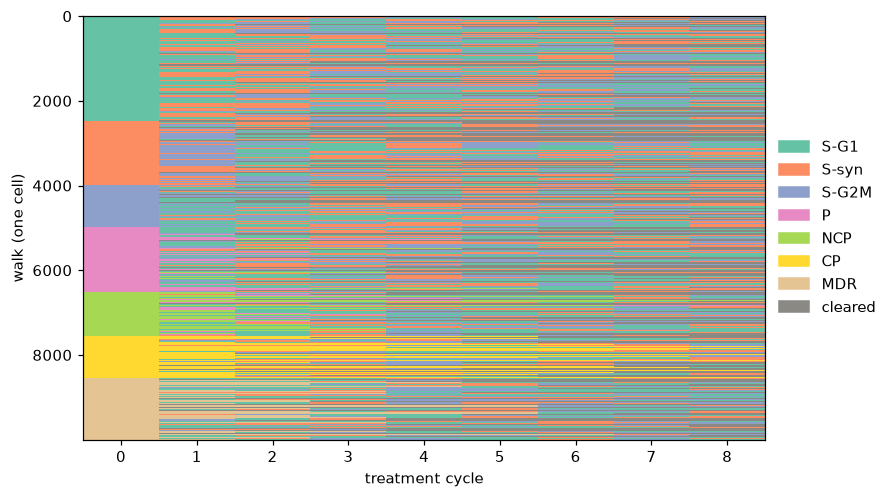

In [28]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [29]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

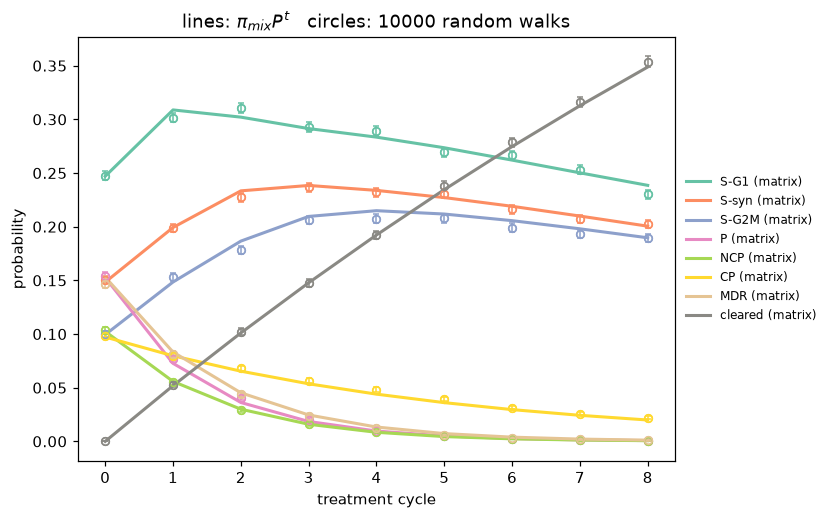

In [30]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

It gets significantly smaller. This is because we have many more cells and are approsimating the probabilities much more closely. In short, we have more information to work with so our probabilities have less uncertainty around them.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [31]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

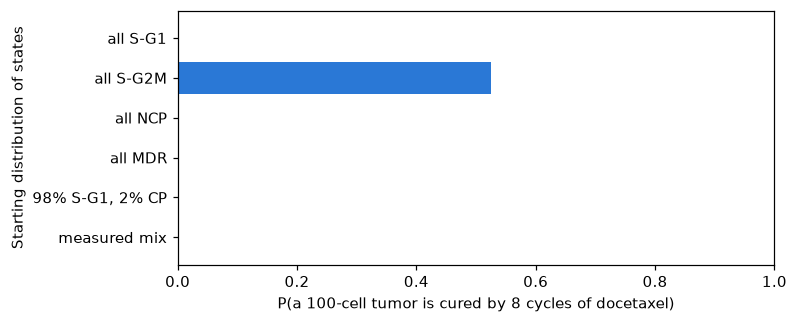

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.660,0.0
all S-G2M,0.525,0.695,0.0
all NCP,0.000,6.545,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.000,7.175,0.0
measured mix,0.000,19.025,0.0


In [36]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

It looks like the only starting distribution of states that is cured by docetaxel is all S-G2M. The rest survive, with MDR having all cells alive and the second closest to cured being all NCP with 6.545 cells alive on average.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

osimertinib: permanently resistant fraction = 0.1148 +/- 0.0010 (SEM)
95% CI: [0.1129, 0.1168]
tumors with > 10% permanently resistant cells: 94%
one-sided t-test vs 10%: t = 14.90, p = 2.42e-27


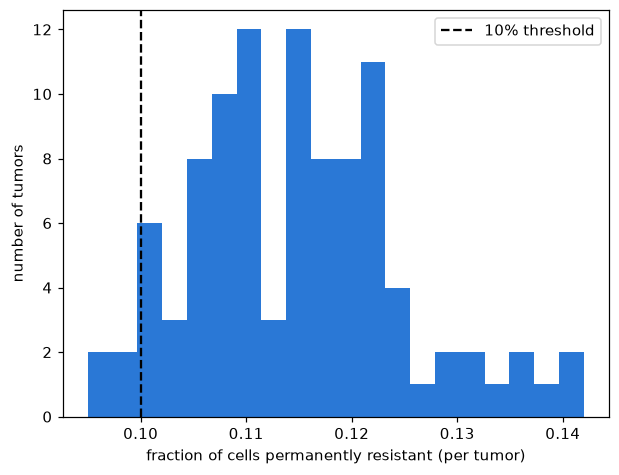

In [40]:
#This code was prompt-coded using claude to write functions.
from scipy import stats

rng = np.random.default_rng(5030)
PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

# write a function that runs 1000 random walks and saves them
def simulate_walks(pi0, schedule, n_cells, rng):
    '''Run n_cells random walks at once. schedule is a list of transition matrices, one per cycle.
    Returns an int array of shape (n_cells, n_cycles + 1): row = one cell's path of state indices.
    Same inverse-CDF method as step(): draw U, pick first state whose cumulative prob exceeds U.'''
    walks = np.empty((n_cells, len(schedule) + 1), dtype=int)
    walks[:, 0] = rng.choice(len(pi0), size=n_cells, p=pi0)          # starting states drawn from pi0
    for t, P in enumerate(schedule):
        cdf = np.cumsum(P, axis=1)[walks[:, t]]                       # each cell's current row, as a CDF
        u = rng.random(n_cells)[:, None]
        walks[:, t + 1] = np.minimum((u > cdf).sum(axis=1), len(OUTCOMES) - 1)
    return walks

# go through each random walk and find the longest consecutive stretch in P or NCP
def longest_persister_run(walks):
    is_persister = np.isin(walks, PERSISTER)
    run = np.zeros(len(walks), dtype=int)
    longest = np.zeros(len(walks), dtype=int)
    for t in range(walks.shape[1]):
        run = np.where(is_persister[:, t], run + 1, 0)
        longest = np.maximum(longest, run)
    return longest

# count up cells that stayed in persister state 3+ consecutive cycles, out of total cells
def fraction_resistant(pi0, schedule, n_cells=1000, rng=rng, min_run=3):
    walks = simulate_walks(pi0, schedule, n_cells, rng)
    return np.mean(longest_persister_run(walks) >= min_run)

# repeat for all tumors: 100 tumors x 1000 cells, 8 cycles of osimertinib, starting from the measured mix
N_TUMORS_PR, N_CELLS_PR, N_CYCLES_PR = 100, 1000, 8
frac_osi = np.array([fraction_resistant(pi_mix, [P_osi] * N_CYCLES_PR, N_CELLS_PR)
                     for _ in range(N_TUMORS_PR)])

# report mean +/- SEM for osimertinib
mean = frac_osi.mean()
sem = frac_osi.std(ddof=1) / np.sqrt(len(frac_osi))
ci = (mean - 1.96 * sem, mean + 1.96 * sem)
print(f"osimertinib: permanently resistant fraction = {mean:.4f} +/- {sem:.4f} (SEM)")
print(f"95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]")
print(f"tumors with > 10% permanently resistant cells: {np.mean(frac_osi > 0.10):.0%}")

# compare to 10% threshold using 95% CI or a hypothesis test
# H0: mean fraction <= 0.10   vs   H1: mean fraction > 0.10
t_stat, p_val = stats.ttest_1samp(frac_osi, 0.10, alternative="greater")
print(f"one-sided t-test vs 10%: t = {t_stat:.2f}, p = {p_val:.2e}")

plt.hist(frac_osi, bins=20, color="#2a78d6")
plt.axvline(0.10, color="k", ls="--", label="10% threshold")
plt.xlabel("fraction of cells permanently resistant (per tumor)")
plt.ylabel("number of tumors"); plt.legend(); plt.show()




In [39]:
# % of tumors with >10% permanently resistant cells, by treatment plan and number of cycles
PLANS = {
    "Osimertinib alone":          lambda n: "O" * n,
    "Docetaxel alone":            lambda n: "D" * n,
    "Alternating OD":             lambda n: ("OD" * n)[:n],
    "Docetaxel, holiday first":   lambda n: "H" + "D" * (n - 1),
}
CYCLES = [4, 6, 8, 12, 16]

pct_over_10, mean_frac = {}, {}
for name, make in PLANS.items():
    pct_over_10[name], mean_frac[name] = {}, {}
    for n in CYCLES:
        sched = [DRUGS[c] for c in make(n)]
        f = np.array([fraction_resistant(pi_mix, sched, N_CELLS_PR) for _ in range(N_TUMORS_PR)])
        pct_over_10[name][n] = np.mean(f > 0.10)
        mean_frac[name][n] = f.mean()

print("fraction of tumors with > 10% PR cells:")
display(pd.DataFrame(pct_over_10).T.rename_axis(columns="cycles").style.format("{:.0%}"))
print("mean PR fraction per tumor:")
display(pd.DataFrame(mean_frac).T.rename_axis(columns="cycles").round(4))


fraction of tumors with > 10% PR cells:


cycles,4,6,8,12,16
Osimertinib alone,86%,93%,90%,92%,96%
Docetaxel alone,11%,14%,17%,24%,11%
Alternating OD,47%,61%,72%,69%,75%
"Docetaxel, holiday first",2%,29%,40%,39%,27%


mean PR fraction per tumor:


cycles,4,6,8,12,16
Osimertinib alone,0.1110,0.1142,0.1150,0.1161,0.1165
Docetaxel alone,0.0873,0.0921,0.0914,0.0922,0.0910
Alternating OD,0.1009,0.1053,0.1060,0.1062,0.1071
"Docetaxel, holiday first",0.0841,0.0938,0.0965,0.0968,0.0954


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

|Prescription|% >10% permanently resistant at 8 cycles|Result of increased cycles|
|------------|----------------------------------------|--------------------------|
|Osimertinib alone|11.42%|No significant change|
|Doxetaxel alone|9.14%|No significant change|
|Alternating OD|10.60%|No significant change|
|Drug Holiday to Doxetaxel|9.65%|No significant change|

Overall, it doesn't look like increasing cycles will have any signififcant impact on the % of tumors that hare 10% permanently resistant. There is noise in these readings that could be decreased with more observations.